In [35]:
# ДЗ 5
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [36]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path

## Исходное изображение и спектр Фурье

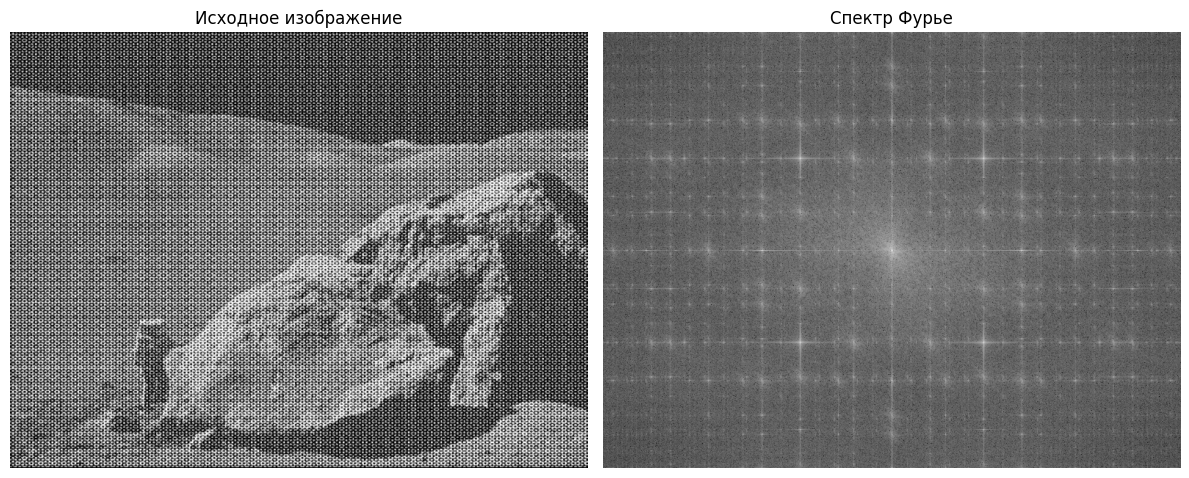

In [37]:
image_path = Path('periodic_noise.JPG')

image_gray = cv.imread(str(image_path), cv.IMREAD_GRAYSCALE)

image_float = image_gray.astype(np.float32)
height, width = image_gray.shape
spectrum = np.fft.fft2(image_float)
spectrum = np.fft.fftshift(spectrum)
log_spectrum = np.log1p(np.abs(spectrum))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(log_spectrum, cmap='gray')
plt.title('Спектр Фурье')
plt.axis('off')

plt.tight_layout()
plt.show()

## Высокочастотная фильтрация на основе ядра Гаусса

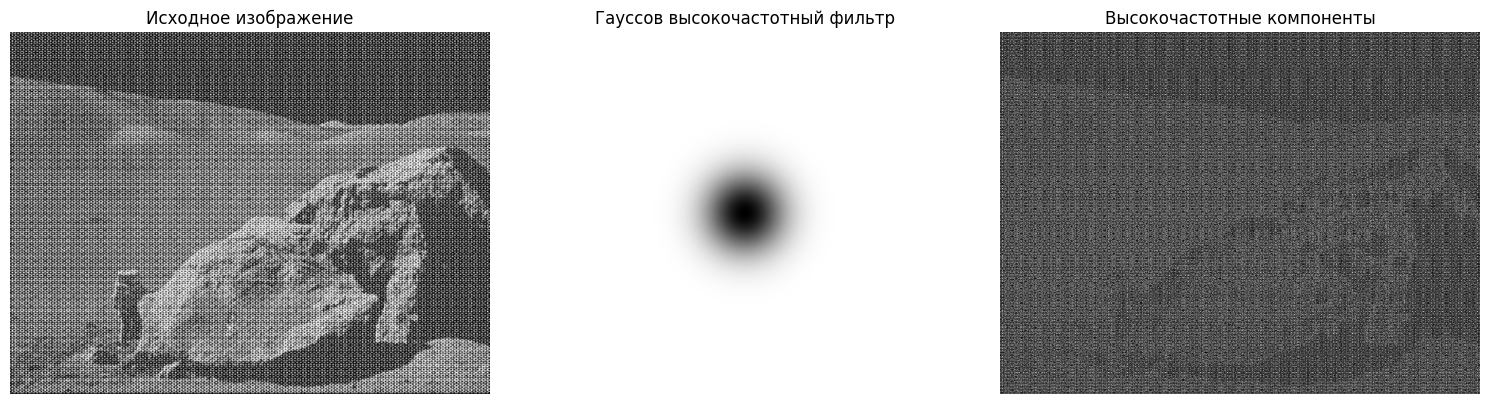

In [38]:
sigma_hp = 45
cy = height // 2
cx = width // 2
y, x = np.ogrid[:height, :width]
radius_sq = ((y - cy)**2 + (x - cx)**2)
highpass_mask = 1.0 - np.exp(-radius_sq / (2.0 * sigma_hp**2))

highpass_fft = spectrum * highpass_mask
highpass_spatial = np.fft.ifft2(np.fft.ifftshift(highpass_fft)).real
highpass_display = cv.normalize(np.abs(highpass_spatial), None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(highpass_mask, cmap='gray', vmin=0, vmax=1)
plt.title('Гауссов высокочастотный фильтр')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(highpass_display, cmap='gray')
plt.title('Высокочастотные компоненты')
plt.axis('off')

plt.tight_layout()
plt.show()

## Вычисление свёртки с помощью преобразования Фурье

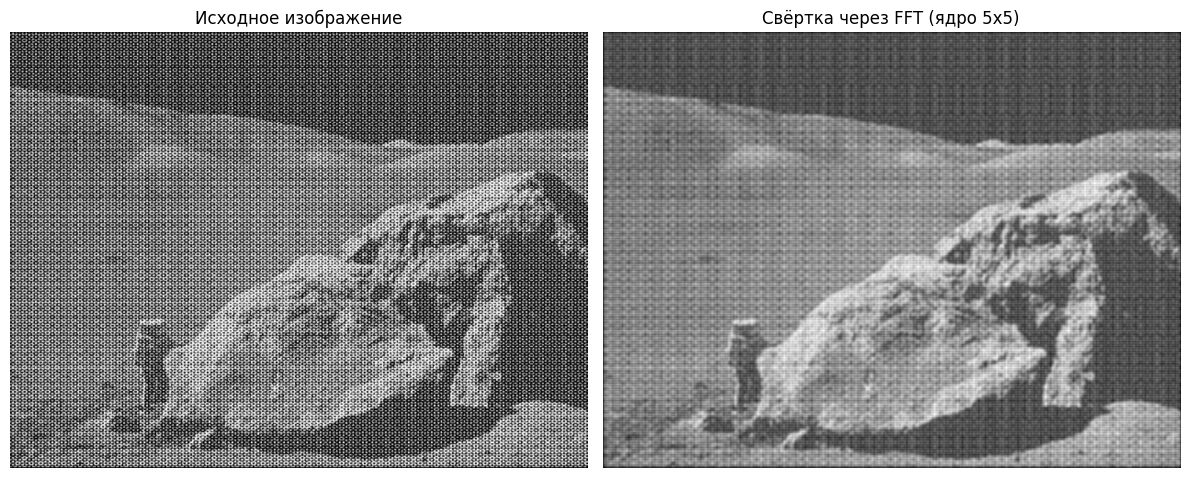

In [39]:
kernel = np.ones((5, 5)) / 25
kh, kw = kernel.shape
fft_shape = (height + kh - 1, width + kw - 1)
image_fft = np.fft.fft2(image_float, s=fft_shape)
kernel_fft = np.fft.fft2(kernel, s=fft_shape)
result_fft = image_fft * kernel_fft
result = np.fft.ifft2(result_fft).real
conv_fft = result[
    kh // 2 : kh // 2 + height,
    kw // 2 : kw // 2 + width
]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(conv_fft, cmap='gray')
plt.title('Свёртка через FFT (ядро 5x5)')
plt.axis('off')

plt.tight_layout()
plt.show()

## Удаление периодического шума с помощью преобразования Фурье

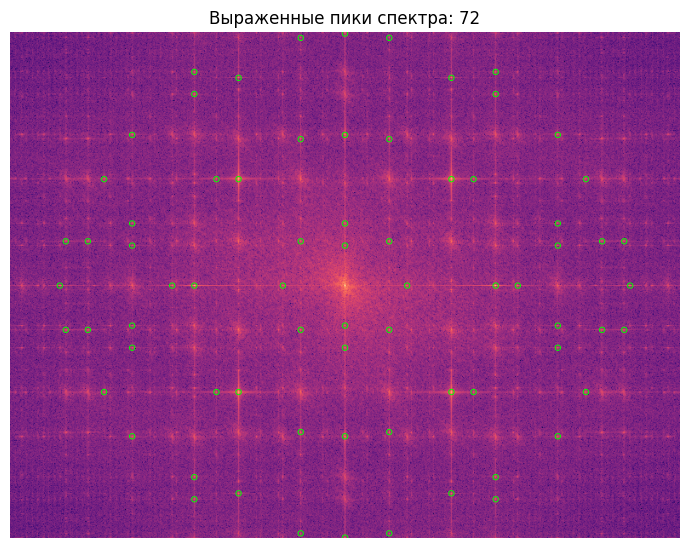

In [40]:
spectral_background = cv.GaussianBlur(log_spectrum.astype(np.float32), (0, 0), 12)
spectral_contrast = (log_spectrum - spectral_background)
local_max = cv.dilate(spectral_contrast, np.ones((11, 11), np.uint8))
peak_threshold = 3.8
center_radius = 30
peak_map = ((spectral_contrast >= local_max - 1e-6) & (spectral_contrast > peak_threshold) & (radius_sq > center_radius**2))
detected_peaks = np.column_stack(np.where(peak_map))

if len(detected_peaks) == 0:
    raise RuntimeError('Частотные пики не найдены')

mirror_peaks = np.column_stack(((2 * cy - detected_peaks[:, 0]) % height, (2 * cx - detected_peaks[:, 1]) % width))
peak_positions = np.unique(np.vstack([detected_peaks, mirror_peaks]), axis=0)

plt.figure(figsize=(7, 6))
plt.imshow(log_spectrum, cmap='magma')
plt.scatter(peak_positions[:, 1], peak_positions[:, 0], s=15, facecolors='none', edgecolors='lime', linewidths=0.7)
plt.title(f'Выраженные пики спектра: {len(peak_positions)}')
plt.axis('off')
plt.tight_layout()
plt.show()

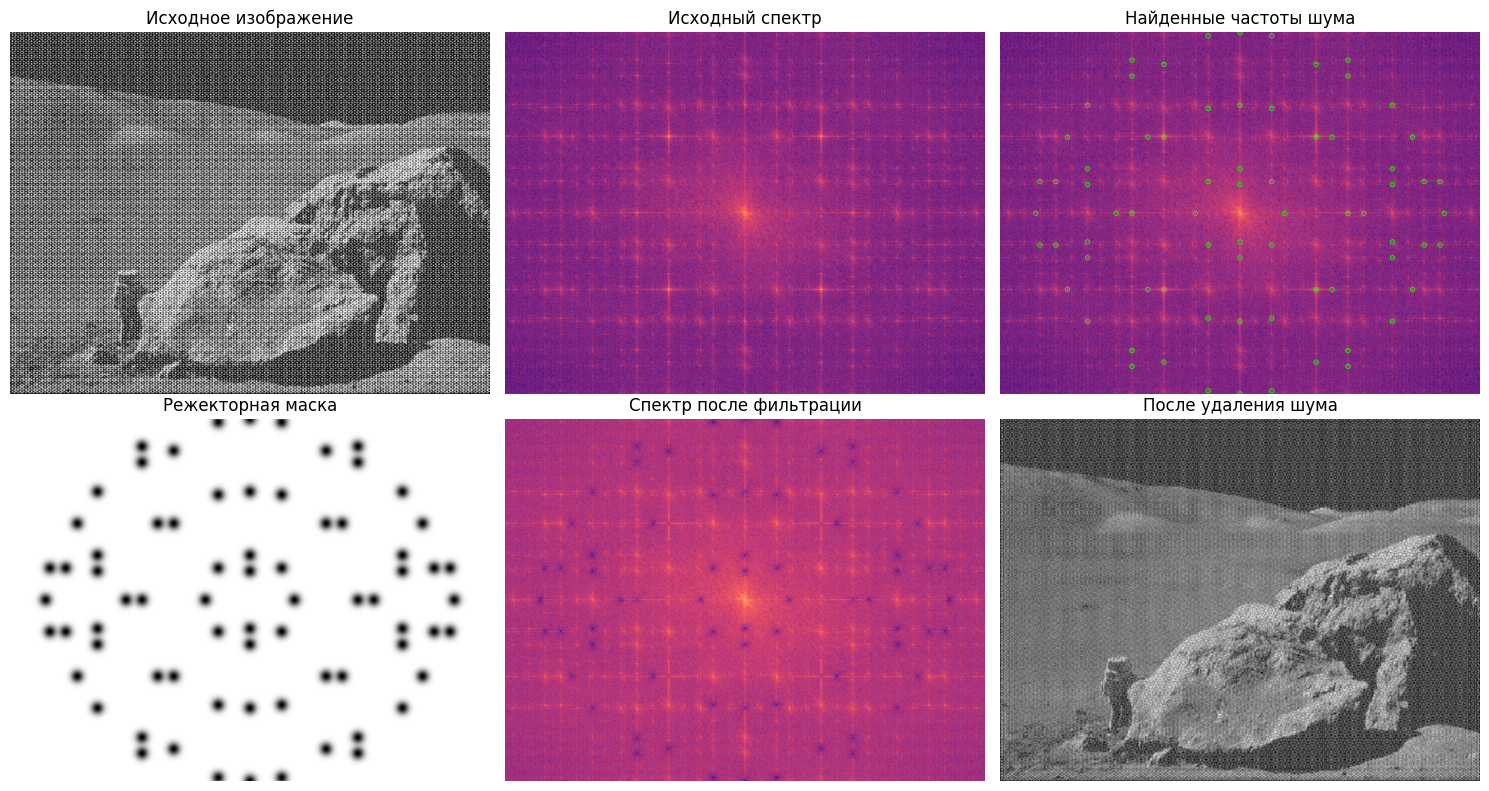

In [41]:
sigma_notch = 7.0
notch_mask = np.ones((height, width), dtype=np.float32)
for py, px in peak_positions:
    distance_sq = ((y - py)**2 + (x - px)**2)
    gaussian_notch = 1.0 - np.exp(-distance_sq / (2.0 * sigma_notch**2))
    notch_mask *= gaussian_notch.astype(np.float32)

filtered_spectrum = spectrum * notch_mask
restored = np.fft.ifft2(np.fft.ifftshift(filtered_spectrum)).real
denoised_image = np.clip(restored, 0, 255).astype(np.uint8)
filtered_log_spectrum = np.log1p(np.abs(filtered_spectrum))

plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1)
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(log_spectrum, cmap='magma')
plt.title('Исходный спектр')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(log_spectrum, cmap='magma')
plt.scatter(peak_positions[:, 1], peak_positions[:, 0], s=10, facecolors='none', edgecolors='lime', linewidths=0.6)
plt.title('Найденные частоты шума')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(notch_mask, cmap='gray', vmin=0, vmax=1)
plt.title('Режекторная маска')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(filtered_log_spectrum, cmap='magma')
plt.title('Спектр после фильтрации')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(denoised_image, cmap='gray', vmin=0, vmax=255)
plt.title('После удаления шума')
plt.axis('off')

plt.tight_layout()
plt.show()

## Сравнение изображения до и после удаления шума

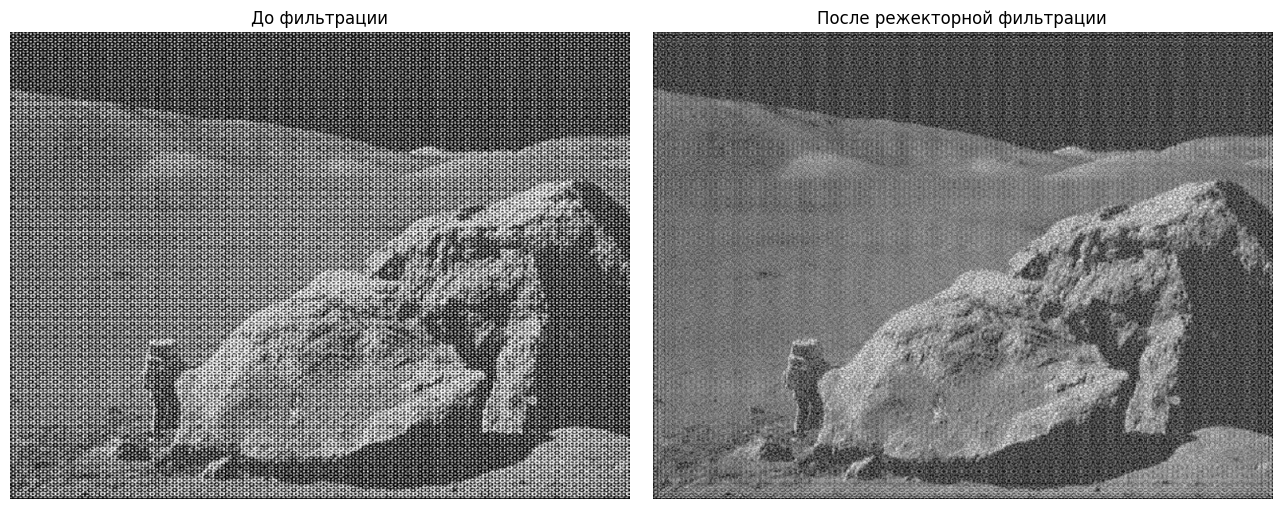

In [42]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title('До фильтрации')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(denoised_image, cmap='gray', vmin=0, vmax=255)
plt.title('После режекторной фильтрации')
plt.axis('off')

plt.tight_layout()
plt.show()
# Режекторная фильтрация уменьшает периодический шум, сохраняя основные детали изображения